# Phase 3: descriptive Theil-Sen trend validation

Stage 2 approval is recorded in [PHASE_2_APPROVAL.md](../phase_reports/PHASE_2_APPROVAL.md).
This notebook reads the completed Phase 3 outputs. Strict 100% remains the default;
Standard 100% is a separate Sahel NDVI comparison; Standard 95% stays experimental.
No preparation input is regenerated, no missing observation is filled, and no
p-values, intervals or significance classifications are computed.

Run `tools/run_science_trends.py` and `tools/validate_science_trends.py` first.
This is a Phase 3 checkpoint, not authorization to start Phase 4.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/architecture/scope.v2.json").exists())
sys.path.insert(0, str(root / "packages/science"))
sys.path.insert(0, str(root / "tools"))
from src.trend_estimation import monthly_elapsed_years, annual_elapsed_years, trend_series
from run_science_trends import stage2_snapshot, assert_no_inference

reports = root / "packages/science/phase_reports"
results = json.loads((reports / "PHASE_3_RESULTS.json").read_text())
validation = json.loads((reports / "PHASE_3_VALIDATION.json").read_text())
tests = json.loads((reports / "PHASE_3_TESTS.json").read_text())
assert len(results["cases"]) == 14
assert tests["passed"] and validation["status"] == "passed"
assert stage2_snapshot() == validation["stage2_sha256"]
assert_no_inference(results)
for case in results["cases"]:
    assert hashlib.sha256((root / case["grid_artifact"]).read_bytes()).hexdigest() == case["grid_sha256"]
print(f"PASS: {tests['tests_run']} tests; {validation['reference_comparisons']} slope-only reference comparisons; "
      f"{validation['stage2_preserved_file_count']} Stage 2 files preserved.")
print(f"Maximum absolute reference difference: {validation['max_absolute_difference']:.3g}")
def show_table(frame):
    display(HTML(frame.to_html(index=False, na_rep="missing", float_format=lambda x:f"{x:.9f}")))

PASS: 72 tests; 210 slope-only reference comparisons; 72 Stage 2 files preserved.
Maximum absolute reference difference: 5.55e-17


## Correct time units and short/missing series

The slope is the median of all finite observation-pair slopes `(y[j]-y[i])/(t[j]-t[i])`.
Time is explicit: monthly calendar-month distances divided by 12, and annual
calendar-year label differences. Missing values drop pairs, preserving their original
time gaps. No implicit monthly axis is used for annual samples.

The shared guard is at least three finite observations. This is a software
computability threshold inherited from the reviewed core, not a validated minimum
for climate evidence. Two-point, singleton, empty and all-missing inputs are
insufficient under this guard. A numerical zero slope has no inference interpretation.

In [2]:
examples = []
for label, values, time in [
    ("Increasing monthly: +1 unit/year", np.arange(48)/12, np.arange(48)/12),
    ("Increasing annual: +1 unit/year", np.arange(8), annual_elapsed_years(np.arange(2001,2009))),
    ("Decreasing annual: -2 units/year", -2*np.arange(8), annual_elapsed_years(np.arange(2001,2009))),
    ("Constant: zero descriptive slope", np.full(8,4.), np.arange(8)),
    ("Missing annual years: preserve gaps", np.array([0.,np.nan,2.,np.nan,4.]), annual_elapsed_years(np.arange(2001,2006))),
    ("Two-point short series", np.array([1.,2.]), np.array([0.,1.])),
]:
    examples.append({"Example":label, **trend_series(values,time)})
show_table(pd.DataFrame(examples)[["Example","slope_per_year","n_valid","valid_span_years","status"]])
print("Annual regression:", tests["annual_factor_of_twelve_regression"])
print("Scalar/grid short-record parity:", tests["explicit_60_point_guard_on_48_samples"])

Example,slope_per_year,n_valid,valid_span_years,status
Increasing monthly: +1 unit/year,1.000000000,48,3.916666667,computed_descriptive
Increasing annual: +1 unit/year,1.000000000,8,7.000000000,computed_descriptive
Decreasing annual: -2 units/year,-2.000000000,8,7.000000000,computed_descriptive
Constant: zero descriptive slope,0.000000000,8,7.000000000,computed_descriptive
Missing annual years: preserve gaps,1.000000000,3,4.000000000,computed_descriptive
Two-point short series,missing,2,1.000000000,insufficient_data


Annual regression: {'truth_per_year': 1.0, 'actual_per_year': 1.0, 'passed': True}
Scalar/grid short-record parity: {'regional_status': 'insufficient_data', 'computable_grid_cells': 0, 'passed': True}


## Twelve delivered strict-policy inputs

Regional slopes are computed from the prepared regional time series, never from
averaged cell slopes. Raw monthly values, matching-calendar-month anomalies and
annual summaries are distinct descriptive estimands. Annual precipitation values
are **annual accumulation in mm**, so the annual slope is change in that annual
accumulation per elapsed year; monthly precipitation slopes concern monthly amounts.
Temperature slopes retain K/year, soil moisture kg m-2/year, and NDVI unitless/year.

In [3]:
strict_rows = []
for case in results["cases"]:
    if case["policy"] != "strict_100":
        continue
    strict_rows.append({"Variable":case["variable_id"], "Region":case["region_id"],
                        "Raw monthly slope/year":case["regional"]["monthly"]["slope_per_year"],
                        "Calendar-anomaly slope/year":case["regional"]["monthly_calendar_anomaly"]["slope_per_year"],
                        "Annual-summary slope/year":case["regional"]["annual"]["slope_per_year"],
                        "Slope units":case["regional"]["annual"]["slope_units"],
                        "Prepared cells":case["grid"]["annual"]["eligible_preparation_cells"]})
show_table(pd.DataFrame(strict_rows))

Variable,Region,Raw monthly slope/year,Calendar-anomaly slope/year,Annual-summary slope/year,Slope units,Prepared cells
air_temperature,nile_corridor,0.047598638,0.030858817,0.025330383,K per year,102
soil_moisture,nile_corridor,0.000008500,0.002485710,0.008890434,kg m-2 per year,459
precipitation,nile_corridor,0.000684342,0.000487028,0.027554997,mm per year,3200
vegetation_greenness,nile_corridor,0.000099519,0.000117963,0.000123811,1 per year,7302
air_temperature,morocco_comparison,0.044953502,0.031111736,0.033175364,K per year,80
soil_moisture,morocco_comparison,-0.104636502,-0.094120016,-0.126120174,kg m-2 per year,287
precipitation,morocco_comparison,-0.282964145,-0.375750053,-8.477351579,mm per year,2500
vegetation_greenness,morocco_comparison,-0.000210735,-0.000201454,-0.000323103,1 per year,3019
air_temperature,sahel_comparison,-0.023212203,-0.013312162,-0.023441038,K per year,160
soil_moisture,sahel_comparison,-0.018854443,-0.031358824,-0.026383742,kg m-2 per year,800


## Sahel NDVI: separate policy outputs

The 14.69%, 82.59% and 99.98% eligibility footprints represent different spatial
samples. Standard 95% also changes the set of contributing cells each month.
Compare slope values descriptively; neither a larger slope nor larger coverage
establishes accuracy or significance.

Policy,Experimental,Eligible area %,Monthly slope (NDVI/year),Annual slope (NDVI/year),Eligible cells,"Complete annual observations per cell, min",Incomplete eligible cell-years excluded
strict_100,False,14.694805611,0.000538262,0.000973724,2961,24.000000000,0
standard_100,False,82.586860501,0.000603252,0.000953649,16531,24.000000000,0
standard_95,True,99.975147514,0.000567989,0.000901538,19995,14.000000000,5157


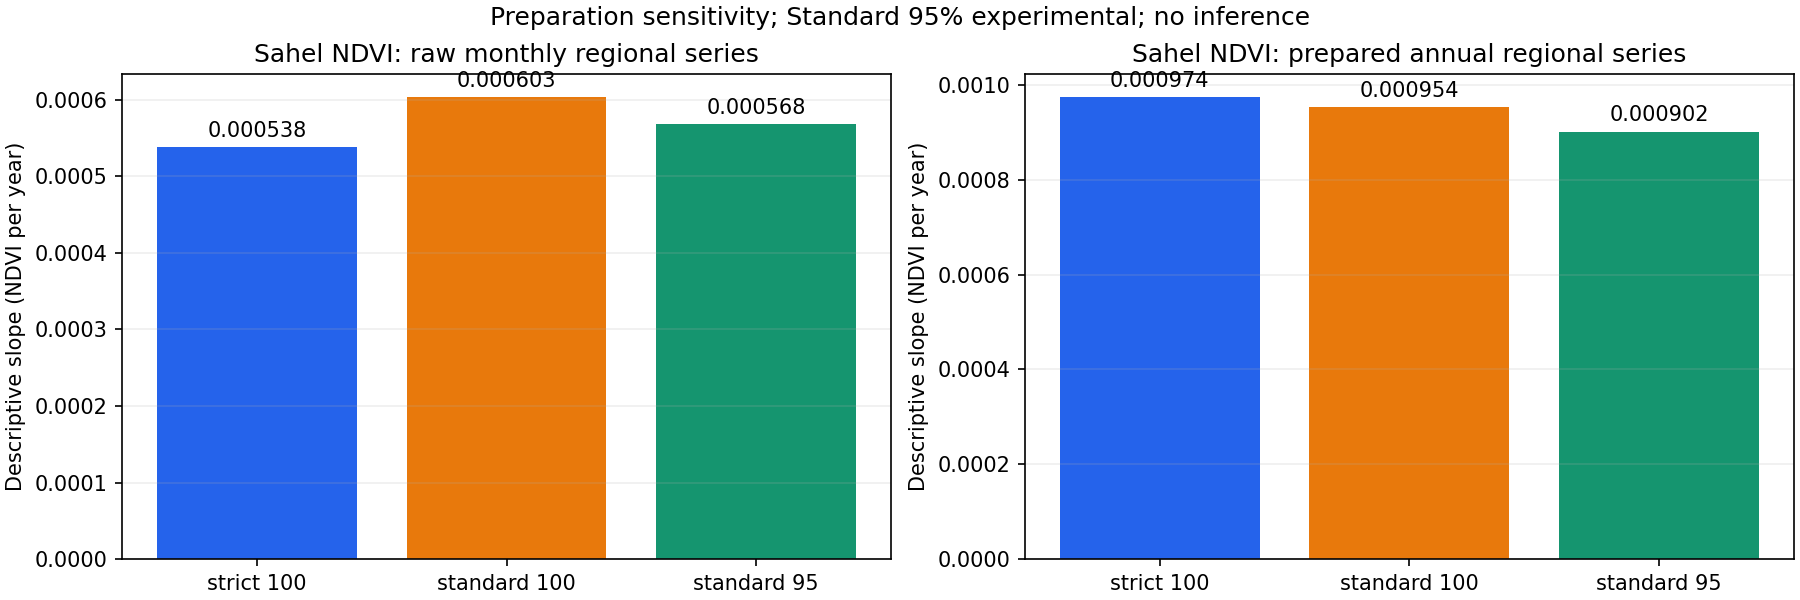

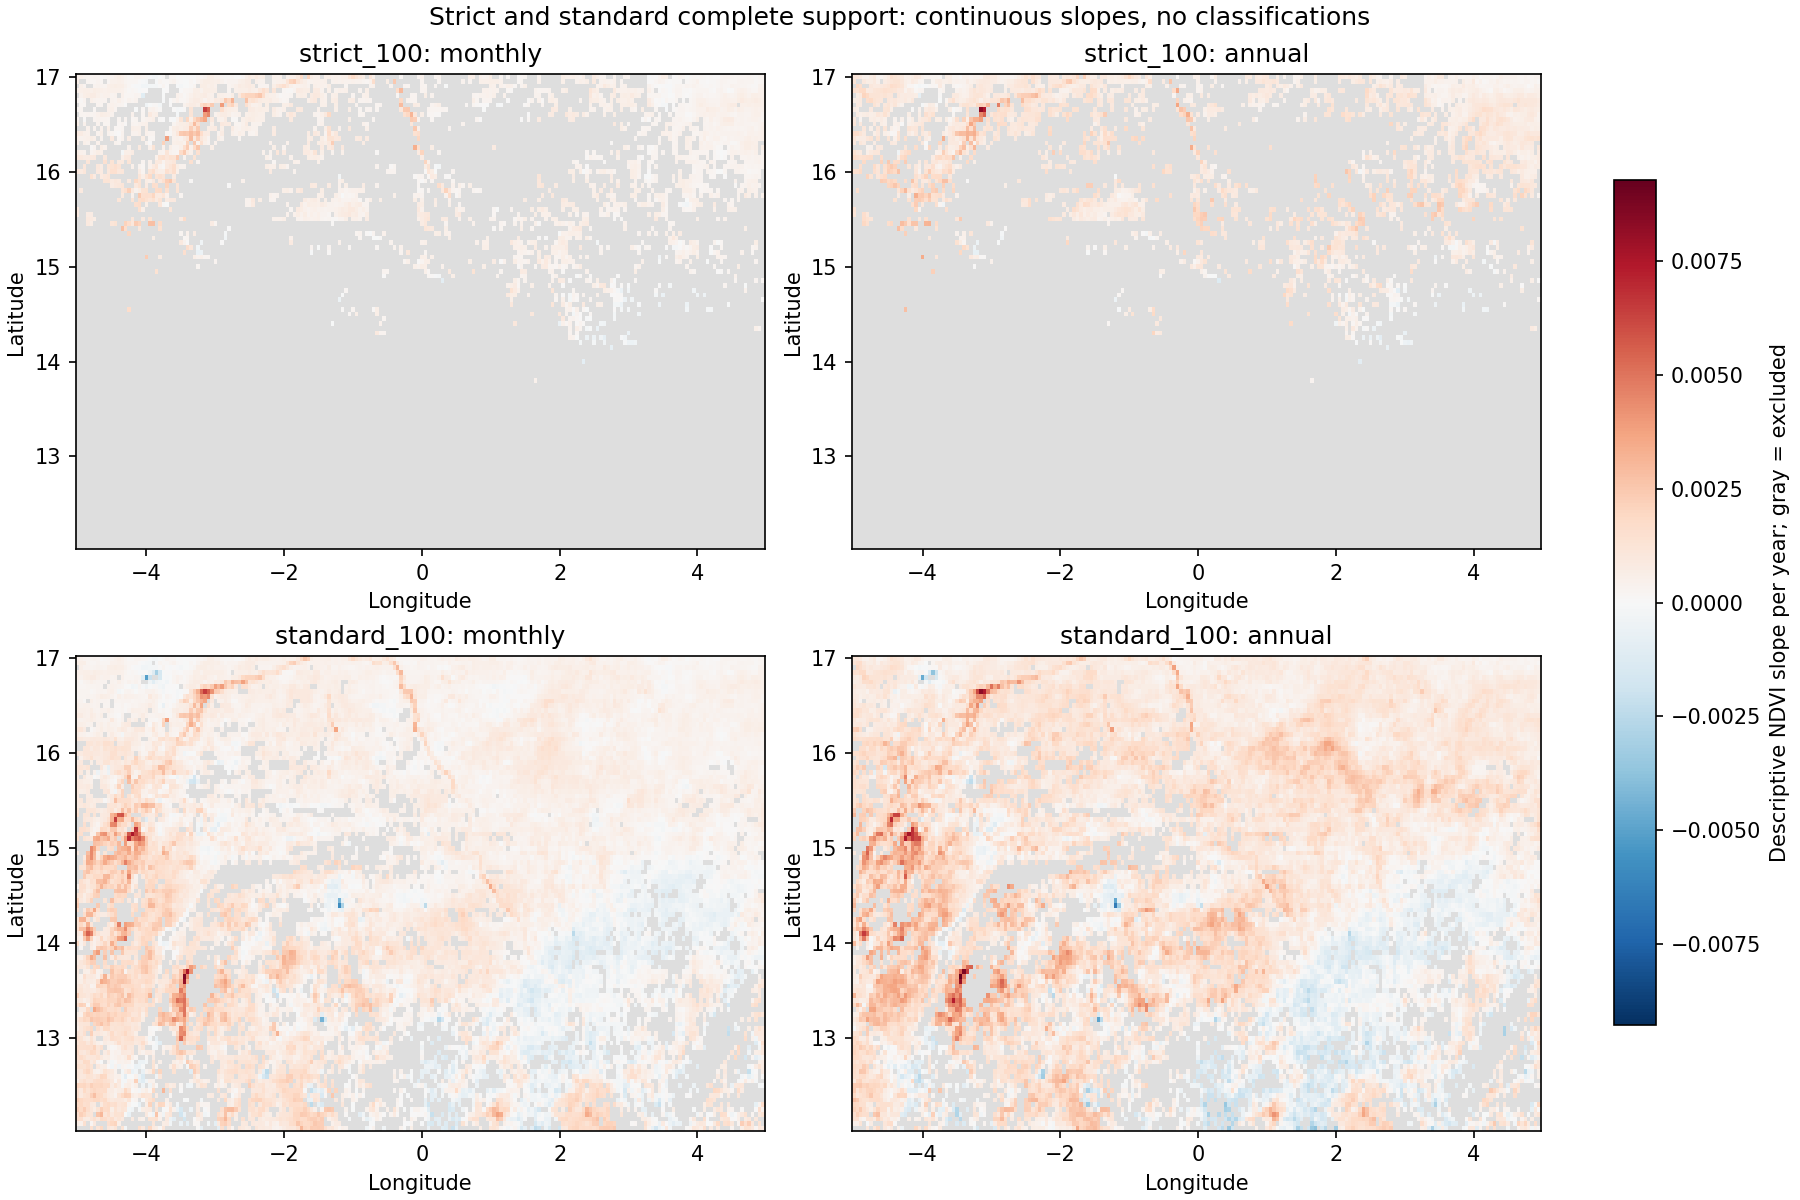

In [4]:
sahel = [case for case in results["cases"] if case["variable_id"] == "vegetation_greenness" and case["region_id"] == "sahel_comparison"]
show_table(pd.DataFrame([{"Policy":c["policy"], "Experimental":c["experimental"],
                         "Eligible area %":c["eligible_area_fraction_selected"]*100,
                         "Monthly slope (NDVI/year)":c["regional"]["monthly"]["slope_per_year"],
                         "Annual slope (NDVI/year)":c["regional"]["annual"]["slope_per_year"],
                         "Eligible cells":c["grid"]["annual"]["eligible_preparation_cells"],
                         "Complete annual observations per cell, min":c["grid"]["annual"]["eligible_valid_observation_count"]["min"],
                         "Incomplete eligible cell-years excluded":c["cell_annual_missing_eligible_records"]} for c in sahel]))
display(Image(filename=str(root / "data/derived/science/phase_3/sahel_policy_slopes.png")))
display(Image(filename=str(root / "data/derived/science/phase_3/sahel_cell_slopes.png")))

## Experimental annual data remain incomplete

For Standard 95%, 5,157 cell-year records are missing and remain excluded from
annual cell slopes. Eligible cells have **14-24 complete annual observations**,
not 24 observations created from partial years. Calendar-year positions are
retained when missing annual observations are omitted from pair calculations.

Its regional annual means use twelve available regional monthly means, whose
spatial supports can differ. The complete-cell-year regional annual diagnostic
uses another spatial sample, which can change between years. These are different
estimands and neither is promoted to the default.

In [5]:
experimental = next(c for c in sahel if c["experimental"])
with xr.open_dataset(root / experimental["grid_artifact"]) as grid:
    counts = grid.annual_n_valid.where(grid.eligible_support.astype(bool)).values
    n, frequency = np.unique(counts[np.isfinite(counts)].astype(int),return_counts=True)
show_table(pd.DataFrame({"Complete annual observations per eligible cell":n,"Number of cells":frequency}))
show_table(pd.DataFrame([{"Experimental annual estimand":name,
                         "Slope (NDVI/year)":experimental["regional"][name]["slope_per_year"]}
                        for name in ["annual","annual_complete_cell_year_diagnostic"]]))
print("All incomplete cell-years remain missing; annual calendar positions are not compressed.")

Complete annual observations per eligible cell,Number of cells
14,1
15,3
16,1
17,7
18,18
19,37
20,93
21,241
22,612
23,2451


Experimental annual estimand,Slope (NDVI/year)
annual,0.000901538
annual_complete_cell_year_diagnostic,0.000878540


All incomplete cell-years remain missing; annual calendar positions are not compressed.


## Tested scope and review boundary

- Known increasing, decreasing and constant signals; analytic/rational references;
  repeating seasonal cycles, outliers, gaps, short/empty records and invalid axes.
- SciPy's slope-only `mstats.sen_seasonal_slopes` used with a single column is an
  ordinary Sen median at regular time positions; it is not a seasonal adjustment
  of these outputs. Masked rows preserve their original distances. No interval-
  generating or hypothesis-test routine is invoked.
- Exact pairwise estimates use quadratic work in record length and bounded batches.
  Real-data validation covers 288 monthly points and 24 annual positions, not an
  unlimited-record performance guarantee.
- Serial dependence, seasonality, preparation selection, changing support and
  shorter annual records can affect interpretation. Reference agreement verifies
  the calculation, not measurement truth or scientific adequacy.

See [PHASE_3_REPORT.md](../phase_reports/PHASE_3_REPORT.md) and the JSON validation
records. Phase 3 stops for review; inference and application readiness remain unchanged.